# Hyperelastic cantilever: load stepping in FEniCSx

The reference beam occupies $\Omega_0=(0,4)\times(0,1)\times(0,1)$ mm$^3$.
Clamp the face $X_1=0$. Apply reference traction $\zeta\boldsymbol t_*$
at $X_1=4$ mm, where $\boldsymbol t_*=(0,-0.02,0)^T$ MPa.
The other faces have zero traction, and there is no body force.
Use a compressible neo-Hookean material with $\mu=1$ MPa and $\lambda=2$ MPa.

![Reference mesh on the face X3 = 0. The beam is 1 mm thick.](figures/beam_setup.png)

Run this example on one process with the **Python (Finite Elements)** kernel.
The saved outputs show a completed run.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import ufl
from mpi4py import MPI
from petsc4py import PETSc

from dolfinx import fem, mesh
from dolfinx.fem.petsc import NonlinearProblem

## Mesh and boundary conditions

Use vector-valued $P_1$ elements on a tetrahedral mesh. Locate the degrees of
freedom on the left face and prescribe zero displacement there. Tag the
loaded face with $1$, so that `ds(1)` integrates only over that face.

In [3]:
domain = mesh.create_box(MPI.COMM_SELF, [[0, 0, 0], [4, 1, 1]], [12, 3, 3])
V = fem.functionspace(domain, ("Lagrange", 1, (3,)))
u = fem.Function(V)
v = ufl.TestFunction(V)
w = ufl.TrialFunction(V)

fdim = domain.topology.dim - 1
left = mesh.locate_entities_boundary(domain, fdim, lambda x: np.isclose(x[0], 0))
right = mesh.locate_entities_boundary(domain, fdim, lambda x: np.isclose(x[0], 4))
clamp_dofs = fem.locate_dofs_topological(V, fdim, left)
bc = fem.dirichletbc(np.zeros(3, dtype=PETSc.ScalarType), clamp_dofs, V)

facet_tags = mesh.meshtags(domain, fdim, np.sort(right),
                          np.ones(len(right), dtype=np.int32))
ds = ufl.Measure("ds", domain=domain, subdomain_data=facet_tags)
dx = ufl.Measure("dx", domain=domain)

## Potential energy, residual, and tangent

With $\boldsymbol F=\boldsymbol I+\operatorname{Grad}\boldsymbol u$ and
$J=\det\boldsymbol F$, the strain-energy density and total potential are
$$
\Psi=\frac{\mu}{2}\bigl(\operatorname{tr}(\boldsymbol F^T\boldsymbol F)-3\bigr)
-\mu\ln J+\frac{\lambda}{2}(\ln J)^2,
\qquad
\Pi_\zeta=\int_{\Omega_0}\Psi\,dV_0
-\zeta\int_{\Gamma_{0t}}\boldsymbol t_*\cdot\boldsymbol u\,dA.
$$
The course convention is $R=\ell-a=-\delta\Pi_\zeta$.
The first derivative below gives $R(\boldsymbol u;\boldsymbol v)$.
The second differentiates $R$ with respect to $\boldsymbol u$ in the
correction direction $\boldsymbol w$, holding $\boldsymbol v$ fixed.

In [4]:
mu, lam = 1.0, 2.0
F = ufl.Identity(3) + ufl.grad(u)
J = ufl.det(F)
psi = mu/2 * (ufl.tr(F.T * F) - 3) - mu * ufl.ln(J) + lam/2 * ufl.ln(J)**2

load = fem.Constant(domain, PETSc.ScalarType(0.0))
traction = ufl.as_vector((0.0, -0.02, 0.0))
Pi = psi * dx - load * ufl.dot(traction, u) * ds(1)
residual = -ufl.derivative(Pi, u, v)
tangent = ufl.derivative(residual, u, w)

## Equilibrium at successive loads

Pass the residual, tangent, and clamp to `NonlinearProblem`. DOLFINx assembles
the forms and PETSc solves the correction equations. Here PETSc uses
backtracking and a direct LU solve for the small linear systems. If the
nonlinear solve fails, the loop stops instead of advancing to the next load.

The load factor stays fixed during each call to `solve()`. The converged
displacement remains in `u` and starts the next solve. Record the mean
downward displacement on the loaded face after each solve:

$$
d_{\mathrm{end}}=-\frac{1}{A_0}\int_{\Gamma_{0t}}u_2\,dA,
\qquad A_0=\int_{\Gamma_{0t}}1\,dA.
$$


In [5]:
solver_options = {
    "snes_type": "newtonls",
    "snes_linesearch_type": "bt",
    "snes_atol": 1e-10,
    "snes_rtol": 1e-8,
    "snes_error_if_not_converged": True,
    "ksp_type": "preonly",
    "pc_type": "lu",
}
problem = NonlinearProblem(
    residual, u, J=tangent, bcs=[bc],
    petsc_options_prefix="cantilever_",
    petsc_options=solver_options,
)

area = fem.assemble_scalar(fem.form(1.0 * ds(1)))
downward_displacement = fem.form(-u[1] * ds(1))
load_factors = [0.25, 0.50, 0.75, 1.0]
end_displacements = []
problem.solver.setConvergenceHistory(reset=True)

u.x.array[:] = 0.0
print("Load factor    Newton iterations    Mean end displacement (mm)")
for zeta in load_factors:
    load.value = zeta
    problem.solve()
    if zeta == load_factors[0]:
        first_displacement = u.x.array.copy()
        first_residuals, _ = problem.solver.getConvergenceHistory()
        first_residuals = first_residuals.copy()
    d_end = fem.assemble_scalar(downward_displacement) / area
    end_displacements.append(d_end)
    iterations = problem.solver.getIterationNumber()
    print(f"{zeta:11.2f} {iterations:20d} {d_end:28.6f}")

Load factor    Newton iterations    Mean end displacement (mm)
       0.25                   20                     0.330589
       0.50                   20                     0.651313
       0.75                   20                     0.952931
       1.00                   20                     1.229509


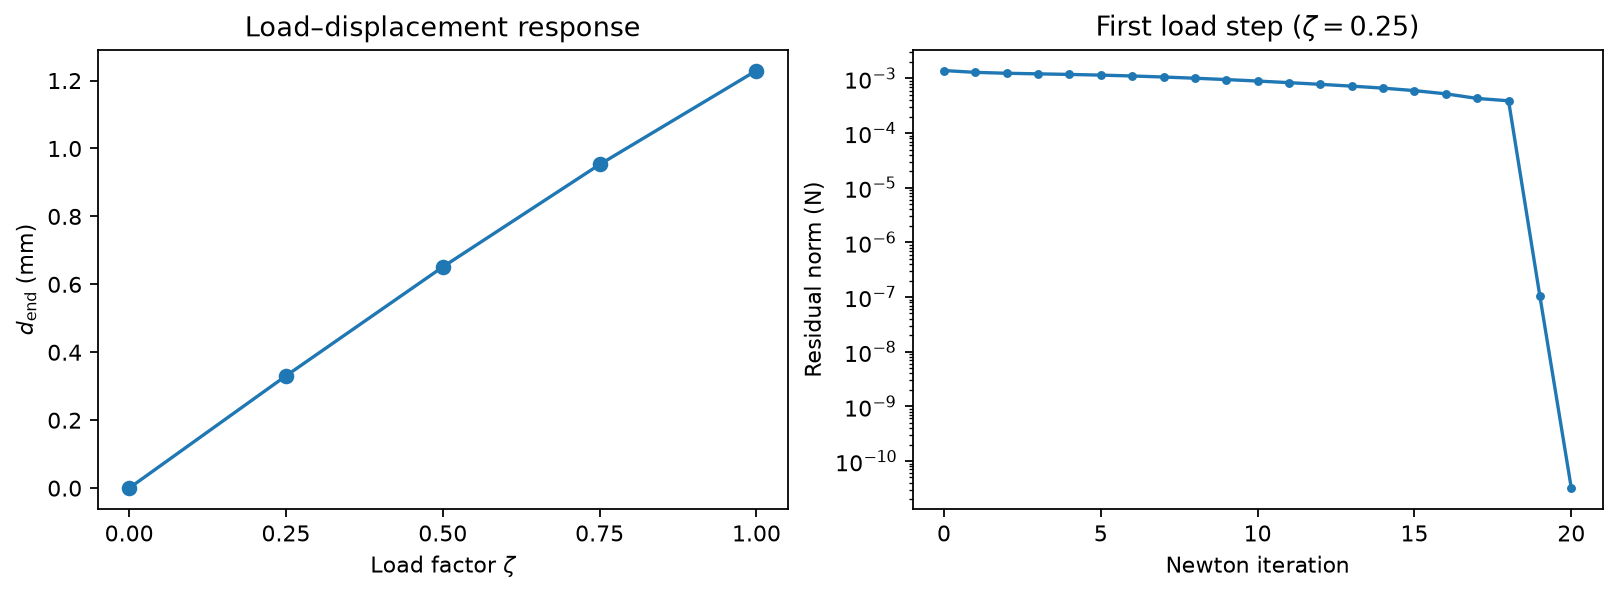

In [6]:
fig, (ax_load, ax_residual) = plt.subplots(1, 2, figsize=(10, 3.6),
                                           dpi=160, layout="constrained")
ax_load.plot([0] + load_factors, [0] + end_displacements, "o-")
ax_load.set(xlabel=r"Load factor $\zeta$", ylabel=r"$d_{\mathrm{end}}$ (mm)",
            title="Load–displacement response", xticks=[0] + load_factors)
ax_residual.semilogy(range(len(first_residuals)), first_residuals, "o-",
                     markersize=3)
ax_residual.set(xlabel="Newton iteration", ylabel="Residual norm (N)",
                title=r"First load step ($\zeta=0.25$)", xticks=range(0, 21, 5))
plt.show()

## Deformed mesh

The gray outline shows the reference beam. The blue mesh
shows the computed position $\boldsymbol x=\boldsymbol X+\boldsymbol u$
at the first and last loads, with no displacement magnification. Both
panels use the same side view.

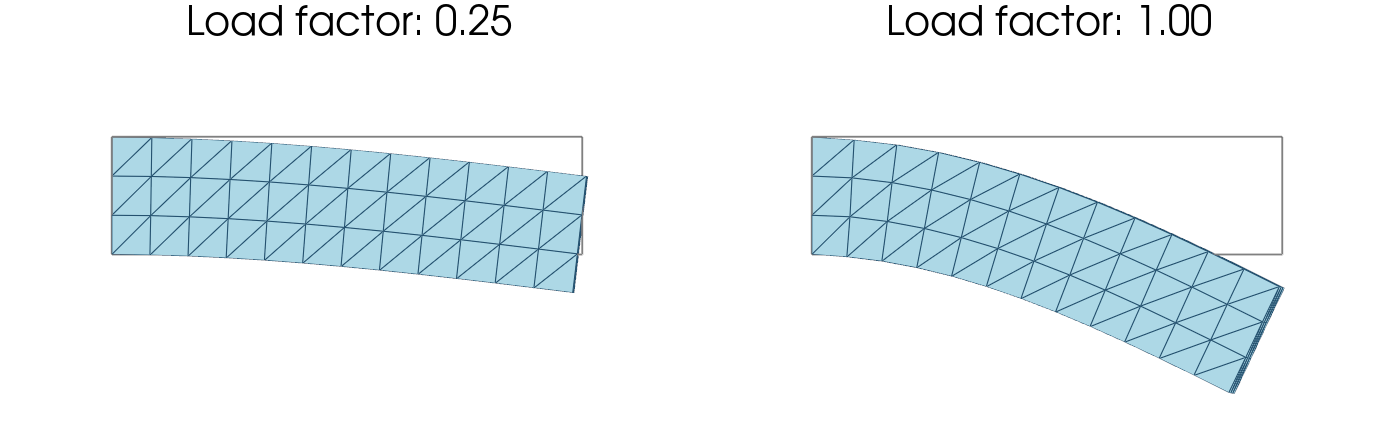

In [7]:
import pyvista as pv
from dolfinx import plot

grid = pv.UnstructuredGrid(*plot.vtk_mesh(V))
viewer = pv.Plotter(shape=(1, 2), window_size=(1400, 430),
                    off_screen=True, border=False)
for panel, (zeta, displacement) in enumerate(
    [(load_factors[0], first_displacement), (load_factors[-1], u.x.array)]
):
    viewer.subplot(0, panel)
    grid.point_data["u"] = displacement.reshape(-1, 3)
    deformed = grid.warp_by_vector("u")
    viewer.add_mesh(deformed, color="lightblue", show_edges=True,
                    edge_color="#24516f", lighting=False)
    viewer.add_mesh(grid.outline(), color="gray", line_width=2)
    viewer.add_text(f"Load factor: {zeta:.2f}", position="upper_edge", font_size=16)
    viewer.view_xy()
    viewer.enable_parallel_projection()
viewer.link_views()
viewer.camera.zoom(1.2)
viewer.show(jupyter_backend="static")

## Check the converged deformation

On an affine $P_1$ tetrahedron, $\operatorname{Grad}\boldsymbol u$ is constant,
so $J$ is constant on each element. Interpolate $J$ into a discontinuous
degree-zero space to get one value per element. This checks the final state;
the solver does not enforce $J>0$ before evaluating every trial residual.
Convergence and a positive determinant do not establish mesh accuracy.

In [8]:
Q = fem.functionspace(domain, ("DG", 0))
J_cell = fem.Function(Q)
J_cell.interpolate(fem.Expression(J, Q.element.interpolation_points))
minimum_J = J_cell.x.array.min()
print(f"Minimum J at full load: {minimum_J:.6f}")
if not minimum_J > 0:
    raise ValueError("The converged deformation has a nonpositive element volume ratio.")

Minimum J at full load: 0.922265


See [DOLFINx `NonlinearProblem`](https://docs.fenicsproject.org/dolfinx/v0.11.0/python/generated/dolfinx.fem.petsc.html#dolfinx.fem.petsc.NonlinearProblem) and Chapter 9 of the course book.